# Analysis of Covid-19 papers

**Master:** Physics of Data \
**Course:** Management and Analysis of Physics Dataset - Module B (MAPD-B) \
**Professor:** Jacopo Pazzini \
**Students:** Polina Gridiaeva, Andres David Rojas Lozano, Elena Niero, Gabriela Landinez Rangel

## Task 3: Title embedding

In this section we want to find the embedding of the papers' titles. This process consists of transforming text into numerical vectors, where each vector represents a word. To do that we have used a pre-trained English model available from the following link: 

https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.en.vec



### Spark set up

In [1]:
from pyspark.sql import SparkSession
cores = 8
ex = 3 
spark = SparkSession.builder \
    .master("spark://master:7077")\
    .appName("COVID-19 task 3")\
    .config('spark.jars.packages', 'org.apache.hadoop:hadoop-aws:3.4.1,org.apache.hadoop:hadoop-common:3.4.1')\
    .config("spark.cores.max", cores*ex) \
    .config("spark.executor.cores", cores) \
    .config("spark.executor.instances", ex) \
    .config("spark.executor.memory", "8g") \
    .config("spark.local.dir", "/mnt/vol2/spark-tmp")\
    .config("spark.worker.dir", "/mnt/vol2/spark-tmp") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config('spark.hadoop.fs.s3a.access.key', 'ACCESS_KEY')\
    .config('spark.hadoop.fs.s3a.secret.key', 'SECRET_KEY')\
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ss1.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .getOrCreate()


sc = spark.sparkContext
sc

:: loading settings :: url = jar:file:/mnt/vol2/env/jup_env/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-aws added as a dependency
org.apache.hadoop#hadoop-common added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f6f296ff-389a-49a6-bd83-7bd3bb8d2302;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-aws;3.4.1 in central
	found software.amazon.awssdk#bundle;2.24.6 in central
	found org.wildfly.openssl#wildfly-openssl;1.1.3.Final in central
	found org.apache.hadoop#hadoop-common;3.4.1 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-protobuf_3_25;1.3.0 in central
	found org.apache.hadoop#hadoop-annotations;3.4.1 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-guava;1.3.0 in central
	found com.google.guava#guava;27.0-jre in c

<SparkContext master=spark://master:7077 appName=Elena>

### Import all the other libraries

In [2]:
import matplotlib.pyplot as plt #for plots
import json #to save/load jsons
import re #for regular expression in cleaning texts
import nltk #for english stopwords
nltk.download('stopwords')
from nltk.corpus import stopwords
import time
import pandas as pd
from pathlib import Path
import os
import sys
os.environ['PYSPARK_PYTHON'] = '/usr/bin/python3'
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
import numpy as np

[nltk_data] Downloading package stopwords to /home/gaby/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Taking files

We take all the files that were cleaned in the Task 0 step.

In [3]:
base_dir = Path("/mnt/vol2/.cache/kagglehub/datasets/allen-institute-for-ai/CORD-19-research-challenge/versions/50/document_parses/")
all_paths = list(base_dir.rglob("*.json"))
print(f"Total JSON files found in disk: {len(all_paths)}")

df_pandas=pd.read_csv('/mnt/vol2/.cache/kagglehub/directory.csv')
valid_files = set(df_pandas['path'])
all_path = [path for path in all_paths if path.name in valid_files]
print(f"Total JSON files to process (filtered): {len(all_path)}")

Total JSON files found in disk: 183369
Total JSON files to process (filtered): 128782


### Title extraction and cleaning

In the following functions we are extracting the titles, creating a vector (paper_id, title) for every paper and cleaning the text from STOPWORDS as we have done in the Task 1.

In [4]:
def extract_title(path):
    try: 
        with open(path) as f:
            doc = json.load(f)
    except Exception:
        return "" # if there are problems (malformations) continue without crashing
    parts = []
    meta = doc.get("metadata", {}) # get metadata fiels, empty dictionary if missing
    paper_id = doc.get("paper_id", path.stem) # if paper_id is absent, get path.stem = returns the file name without extensions (without ".json")
    title = meta.get("title", "") # title is inside meta, empty string if missing
    return (paper_id, title) # returning tuple

LATEX_STOPWORDS = {
    "usepackage","documentclass","documentstyle","newcommand",
    "renewcommand","def","let","newenvironment","setlength","setcounter",
    "addtolength","oddsidemargin","evensidemargin","textwidth","textheight",
    "topmargin","amsmath","amssymb","amsfonts","amsbsy","amsthm","amscd",
    "mathrsfs","mathtools","upgreek","wasysym","eucal","includegraphics",
    "bibliographystyle","bibliography","cite","ref","label","caption",
    "footnote","textbf","textit","emph","hline","vspace","hspace","noindent",
    "centering","linewidth","columnwidth","document","minimal",
    "figure","table","equation","align","array","itemize","enumerate",
}

STOPWORDS = set(stopwords.words('english')) | LATEX_STOPWORDS # union between standard english stopwords and latex stopwords. Sets are changeable.

def clean_text(text):
    cleaned_text = re.findall(r'[a-z]{3,}', text.lower()) #lowercases the whole input and finds words with at least 3 letters from a to z. 
    return [t for t in cleaned_text if t not in STOPWORDS] # returns a list of strings [word1, ..., wordn] with the words that are not in stopwords. Lists are unchangeable. 

Now the RDD can be created by parallelizing the paths that bring to the files we want to embed. After parallelizing, the "extract_title" function is applied through map, in this way for every file we get a tuple (paper_id, title). Since now the data are in a (key,value)-format we can use mapValues to apply "clean_text" to every title. In order to keep in memory the full titles, in mapValues a new tuple composed of (title, clean_text(title)=[word1, ..., wordn]) is created.

Finally, we persist our RDD, in this way it is saved in memory through the entire life of our application and is not recomputed every time we use it.

In [5]:
titles_rdd = (sc.parallelize(all_path, numSlices=48)
    .map(extract_title)
    .mapValues(lambda title: (title, clean_text(title)))
             )

titles_rdd.persist()

PythonRDD[1] at RDD at PythonRDD.scala:58

### Vocabulary creation

To create our embedding we need to load the standard English model contained in the file wiki.en.vec. Since this file is big we decided to proceed in an alternative way. 

First of all we extracted all the unique words that are contained in the titles in order to create a sort of vocabulary. We broadcast our vocabulary to every executor, in order to open the wiki.en.vec file in a parallelized way using textFile.

Then we create a new RDD ("filtered_vecs") removing the first line, which contains the number of words and size of the vectors, and keeping just the embedding of the words we need (that are contained in the vocabulary we broadcasted earlier). Using the "parse_line" function we get for every word a vector in the form: (word, [embedding]). 

Finally, the "filtered_vecs" RDD is converted into a dictionary which is broadcasted through all the executors, ready for the true embedding.


In [6]:
def parse_line(line):
    tokens = line.rstrip().split(' ') #rstrip = removes the \n character at the end, split = split the string into single words ['word1', ..., 'wordn']
    return (tokens[0], [float(x) for x in tokens[1:]])

In [7]:
#titles_rdd is in the form (paper_id, (title, [word1, ... , wordn]))
vocab_set = set(titles_rdd.flatMap(lambda kv: kv[1][1]).distinct().collect())

print(f"Vocabulary size: {len(vocab_set)}")

bc_vocab = sc.broadcast(vocab_set)

vec_path = "/mnt/vol2/.cache/kagglehub/wiki.en.vec"

vec_rdd = sc.textFile(vec_path, minPartitions=48)
header = vec_rdd.first()

filtered_vecs = (
    vec_rdd
    .filter(lambda l: l != header) #lazy
    .map(parse_line) #lazy
    .filter(lambda kv: kv[0] in bc_vocab.value) #lazy
)

vecs_dict = dict(filtered_vecs.collect()) #action
embeddings_bc = sc.broadcast(vecs_dict)

Vocabulary size: 53447


### Title embedding

The actual title embedding is done through the following functions. In the "title_embedding" function firstly we compute the matrix composed of:

[ 

[embedding_vector_word1], 

..., 

[embedding_vector_wordn] 

]

To avoid differencies in dimensionality and to use the embeddings for the following Task 4, we decided to compute the average along the columns of this matrix. In this way we get a vector of 300 numbers for every paper.

In [8]:
def title_embedding(text):
    vecs = [embeddings_bc.value[t] for t in text if t in embeddings_bc.value] #returns the embedding vectors (embeddings_bc.value[t]) for every word in [word1, ..., wordn] in the form of a matrix.
    if not vecs:
        return None # this preserves from null, incorrect or not english titles!
    dim = len(vecs[0]) # 300
    avg = [0.0] * dim
    for v in vecs:
        for i in range(dim):
            avg[i] += v[i] # sum all the i-th elements of every word embedding vector.
    return [x / len(vecs) for x in avg]

# The "titles_rdd" at this point is in the form (paper_id, (title, [word1, ..., wordn])). 
#Inside the function "titles" we run a mapValues where to perform the embedding.
def titles(sc, rdd):
    t0 = time.time()
    
    titles_emb = (
        rdd
        .mapValues(lambda title: (title[0], title_embedding(title[1])))
    ) # title[0] = raw title from titles_rdd, title[1] = [word1, ..., wordn]
    
    total_titles = titles_emb.count() #action
    
    elapsed = time.time()-t0 #after .count!! otherwise the time is always 0
    
    return titles_emb, total_titles, elapsed

In [9]:
#The "titles_rdd" at this point is in the form (paper_id, (title, [word1, ..., wordn]))
titles_emb_rdd, total_titles, elapsed = titles(sc, titles_rdd) # returns (paper_id, (title, embedding))
titles_embs = titles_emb_rdd.map(lambda kv: (kv[0], kv[1][0], kv[1][1])).collect()

In [10]:
print(f"Total titles: {total_titles}")
print(f"Titles with a valid embedding: {sum(1 for e in titles_embs if e[2] is not None)}")
print(f"Titles with None (no words matched): {sum(1 for e in titles_embs if e[2] is None)}")

# peek at one
for idi, text, emb in titles_embs[:5]:
    if emb is not None:
        print(f"Title: {text!r}")
        print(f"Id: {idi}")
        print(f"  dim: {len(emb)}, first 5 values: {emb[:5]}")
    else:
        print(f"Title: {text!r} -> None (no vocab overlap)")

Total titles: 128782
Titles with a valid embedding: 128547
Titles with None (no words matched): 235
Title: 'A signal-flexible gene diagnostic strategy coupling loop-mediated isothermal amplification with hybridization chain reaction'
Id: 3703093f16e819c54aba603f7d7062d8a23c0d0c
  dim: 300, first 5 values: [0.005553161538461538, 0.12718033076923077, -0.17589246153846153, 0.1881720769230769, -0.2738168461538461]
Title: 'Supplementary Materials: Design, Synthesis and Biological Evaluation of Novel Primaquine-Cinnamic Acid Conjugates of Amide and Acylsemicarbazide Type'
Id: fd738b997979c4b38c3a9aaa1b148a090fe94613
  dim: 300, first 5 values: [0.06379715384615385, 0.04148723076923077, -0.2877751076923077, 0.08571023076923077, -0.3745315384615384]
Title: 'Severity Prediction for COVID-19 Patients via Recurrent Neural Networks'
Id: 09ce9181b6691229a1eef254eeb53d81c5361c6a
  dim: 300, first 5 values: [0.051140875, 0.018831749999999994, -0.13710062500000003, 0.32930250000000005, -0.190131749999

In [7]:
#saving in a json file
output_path = "/mnt/vol2/.cache/kagglehub/paper_embeddings.jsonl"
n_saved = 0
with open(output_path, "w") as f:
    for paper_id, text, emb in titles_embs:
        if emb is not None:
            f.write(json.dumps({"paper_id": paper_id, "title_name": text, "embedding": emb}) + "\n")
            n_saved += 1
print(f"Saved {n_saved} embeddings to {output_path}")

Saved 128547 embeddings to /mnt/vol2/.cache/kagglehub/paper_embeddings.jsonl


In [11]:
spark.stop()

RDDs and broadcasted variables are not saved after killing the application.

# Benchmarking

Once the process baseline was established, we proceeded to iterate over the pipeline using different configurations for the number of partitions in the `parallelize` method. We tested multiple values relative to the total number of available cores ($x$), specifically using $[1/3x, 2/3x, x, 2x, 4x, 8x]$. This benchmark was repeated across different cluster configurations of executors and cores, keeping the total core count constant at 24:

* 3 executors with 8 cores each
* 6 executors with 4 cores each
* 12 executors with 2 cores each

To ensure statistical reliability, we measured the average execution time across multiple runs ($n=5$) for each specific configuration, allowing for a subsequent analysis and comparison between the runs.

In [29]:
n_executors = 3 # 12, 6      
cores_per_executor = 8#  2, 4

spark = SparkSession.builder \
    .master("spark://master:7077")\
    .appName("COVID-19 task 3")\
    .config('spark.jars.packages', 'org.apache.hadoop:hadoop-aws:3.4.1,org.apache.hadoop:hadoop-common:3.4.1')\
    .config("spark.cores.max", cores_per_executor*n_executors) \
    .config("spark.executor.cores", cores_per_executor) \
    .config("spark.executor.instances", n_executors) \
    .config("spark.executor.memory", "3g") \
    .config("spark.local.dir", "/mnt/vol2/spark-tmp")\
    .config("spark.worker.dir", "/mnt/vol2/spark-tmp") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config('spark.hadoop.fs.s3a.access.key', '79f100fb66c34d338833171110cb12fe')\
    .config('spark.hadoop.fs.s3a.secret.key', '--------------------------------')\
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .getOrCreate()

sc = spark.sparkContext
sc

26/07/11 10:55:28 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


<SparkContext master=spark://master:7077 appName=Elena>

In [30]:
embeddings_bc = sc.broadcast(vecs_dict)  # the broadcasted variables are not saved after killing of the previous applications.

In [31]:
partition_values = [8, 12, 24, 48, 72] 
n_repeats = 5
all_results = []

for n in partition_values:
    titles_rdd = (sc.parallelize(all_path, numSlices=n)
        .map(extract_title) # to be done inside the loop to change numSlices
        .mapValues(lambda title: (title, clean_text(title)))
                 )
    titles_rdd.persist()
    
    for rep in range(n_repeats):
        print(f"Run with {n} partition values {rep+1} time: ")
        titles_emb_rdd, total_titles, elapsed = titles(sc, titles_rdd)
        all_results.append({
            "num_executors": n_executors,
            "cores_per_executor": cores_per_executor,
            "total_cores": n_executors * cores_per_executor,
            "num_partitions": n,
            "rep": rep+1,
            "time_sec": elapsed
        })
        print(f"partitions={n} rep={rep+1} time={elapsed:.2f}s")
        
    titles_rdd.unpersist()

df = pd.DataFrame(all_results)
df.to_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task3_3_8.csv", index=False)
print("Saved!")
print(df)

Run with 8 partition values 1 time: 


26/07/11 10:56:01 WARN TaskSetManager: Stage 0 contains a task of very large size (1213 KiB). The maximum recommended task size is 1000 KiB.
26/07/11 10:57:16 WARN TaskSetManager: Stage 1 contains a task of very large size (1292 KiB). The maximum recommended task size is 1000 KiB.


partitions=8 rep=1 time=74.46s
Run with 8 partition values 2 time: 


26/07/11 10:57:20 WARN TaskSetManager: Stage 2 contains a task of very large size (1292 KiB). The maximum recommended task size is 1000 KiB.


partitions=8 rep=2 time=4.13s
Run with 8 partition values 3 time: 


...

partitions=72 rep=2 time=2.93s
Run with 72 partition values 3 time: 


partitions=72 rep=3 time=2.69s
Run with 72 partition values 4 time: 


partitions=72 rep=4 time=2.66s
Run with 72 partition values 5 time: 


[Stage 24:=======================================================>(71 + 1) / 72]

partitions=72 rep=5 time=2.75s
Saved!
    num_executors  cores_per_executor  total_cores  num_partitions  rep  \
0               3                   8           24               8    1   
1               3                   8           24               8    2   
2               3                   8           24               8    3   
3               3                   8           24               8    4   
4               3                   8           24               8    5   
5               3                   8           24              12    1   
6               3                   8           24              12    2   
7               3                   8           24              12    3   
8               3                   8           24              12    4   
9               3                   8           24              12    5   
10              3                   8           24              24    1   
11              3                   8           24            

In [33]:
spark.stop()

Actually, the first repetition for every configuration was taking much more time than the other 4. Indeed, in the first repetition we are calculating the time it is needed to construct the RDD too, which than is saved for all the other repetition thanks to persist. So we are averaging just in the last 4 repetition, considering the first one as an outlier.

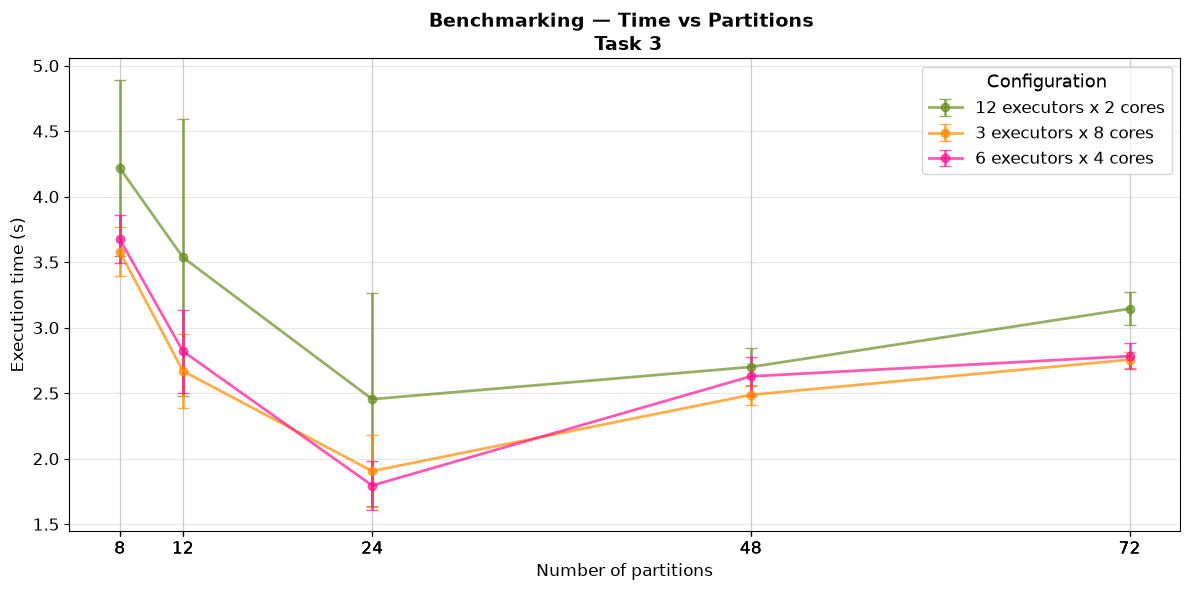

In [3]:
df1 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task3_12_2.csv")
df2 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task3_3_8.csv")
df3 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task3_6_4.csv")

df_all = pd.concat([df1, df2, df3], ignore_index=True)

df_clean = df_all[df_all['rep'] != 1]

df_avg = (
    df_clean
    .groupby(['num_executors', 'cores_per_executor', 'num_partitions'])['time_sec']
    .agg(mean_time='mean', std_time='std', n='count')
    .reset_index()
)
df_avg['sem_time'] = df_avg['std_time'] / np.sqrt(df_avg['n'])

configs = [(12, 2), (3, 8), (6, 4)]
colors = [ 'olivedrab','darkorange' ,'deeppink']
labels = ['12 executors x 2 cores', '3 executors x 8 cores', '6 executors x 4 cores']

plt.figure(figsize=(12, 6))
for (n_ex, n_c), color, label in zip(configs, colors, labels):
    subset = df_avg[
        (df_avg['num_executors'] == n_ex) &
        (df_avg['cores_per_executor'] == n_c)
    ].sort_values('num_partitions')
    plt.errorbar(subset['num_partitions'], subset['mean_time'],
                 yerr=subset['sem_time'],
                 marker='o', color=color, alpha = 0.7, label=label,
                 linewidth=2, capsize=4)
plt.xticks(df_avg['num_partitions'], fontsize = 12)
plt.yticks(fontsize=12)
plt.xlabel('Number of partitions', fontsize = 12)
plt.ylabel('Execution time (s)', fontsize = 12)
plt.title('Benchmarking — Time vs Partitions \n Task 3', fontsize = 14, fontweight = 'bold')
plt.legend(title='Configuration', fontsize = 12, title_fontsize = 13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/mnt/vol2/.cache/kagglehub/benchmarking_csv/plots/benchmark_plot_task3.png', dpi=150)
plt.show()